In [100]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False#图像显示
#机器学习
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder,OneHotEncoder,StandardScaler


In [99]:
#一.总体特征分析
df = (pd.read_csv('hotel_bookings.csv'))
df.info()
df.describe()
#数据集的 31 个特征可划分为预订基础信息、入住宾客与住宿时长、客源渠道、客户历史预订行为、房间信息、押金排队信息、价格与特殊需求、订单结局状态八大类。

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [101]:
# 二、缺失值处理
#1.每列特征缺失样本数量
print('     特征缺失数')
print(df.isnull().sum()[df.isnull().sum() > 0])
#2.每列特征值缺失占比
print('     特征缺失率')
print((df.isnull().sum() / len(df) * 100).round(2).sort_values(ascending=False).pipe(lambda s: s[s > 0]))
#3.字符型数据取值个数
print('     字符型特征取值个数')
for col in df.select_dtypes(include=['object', 'string']).columns:
    print(f"{col}: {df[col].nunique()} 个取值")

     特征缺失数
children         4
country        488
agent        16340
company     112593
dtype: int64
     特征缺失率
company    94.31
agent      13.69
country     0.41
dtype: float64
     字符型特征取值个数
hotel: 2 个取值
arrival_date_month: 12 个取值
meal: 5 个取值
country: 177 个取值
market_segment: 8 个取值
distribution_channel: 5 个取值
reserved_room_type: 10 个取值
assigned_room_type: 12 个取值
deposit_type: 3 个取值
customer_type: 4 个取值
reservation_status: 3 个取值
reservation_status_date: 926 个取值


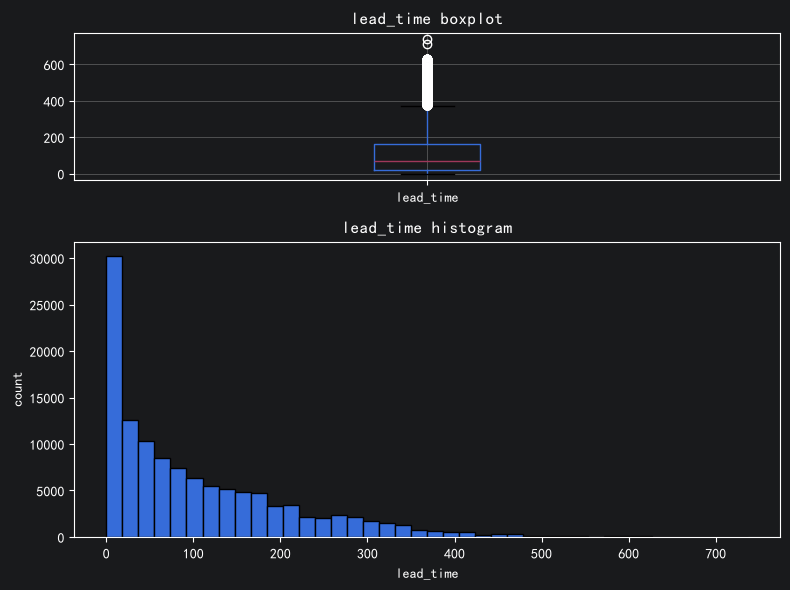

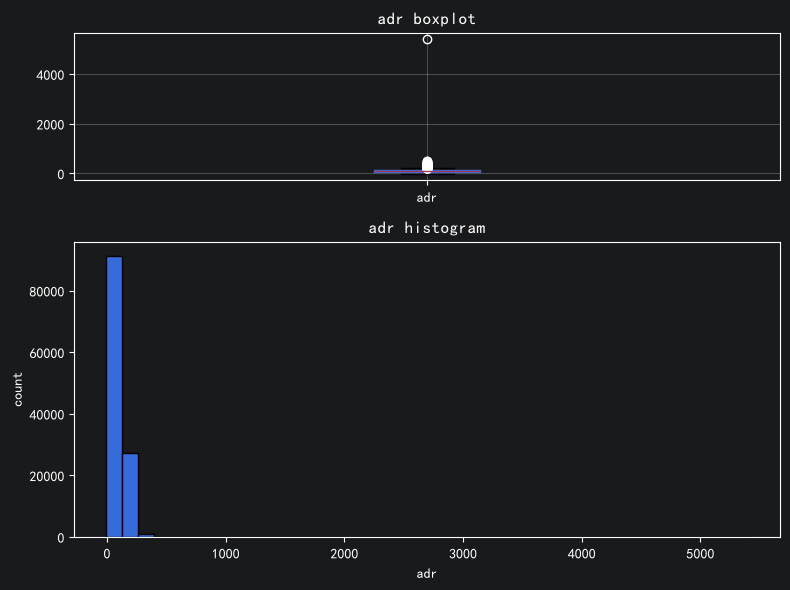

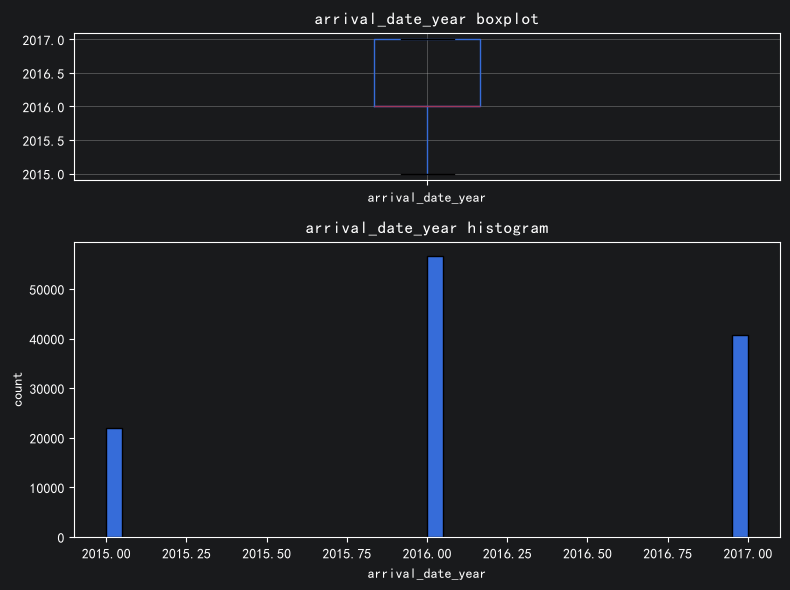

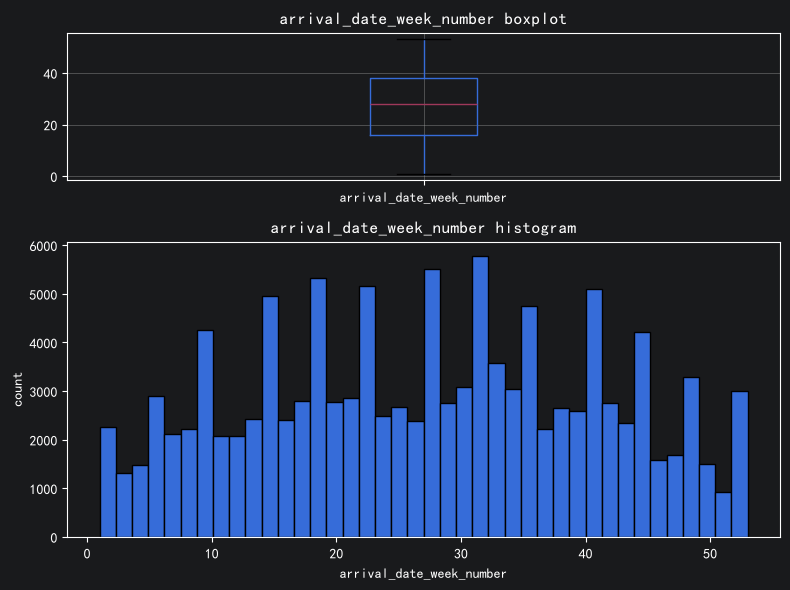

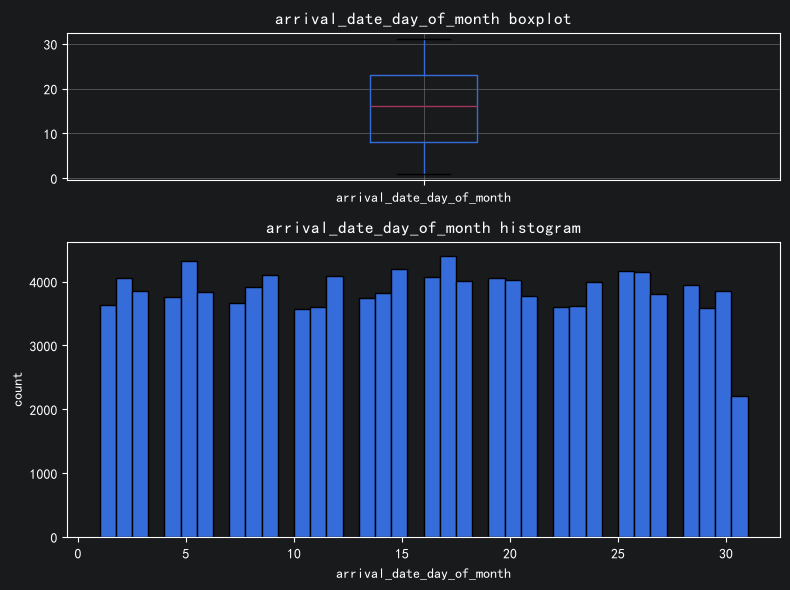

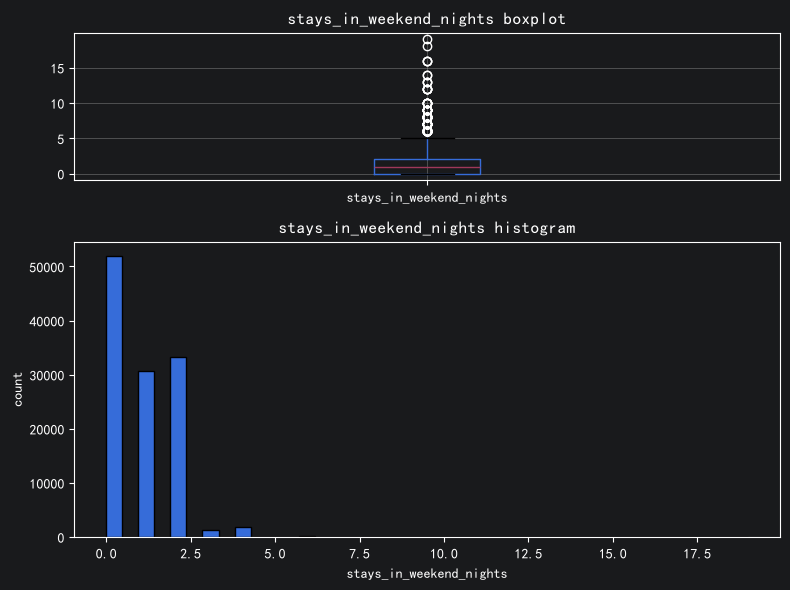

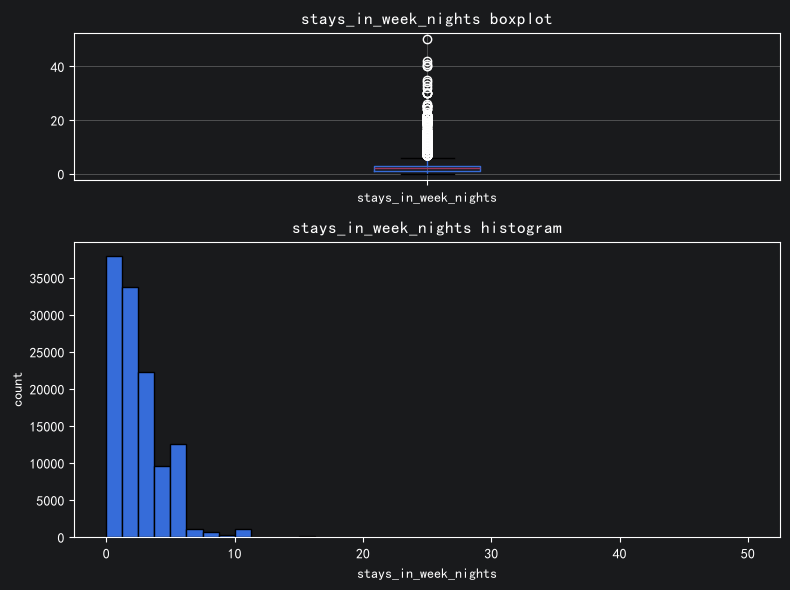

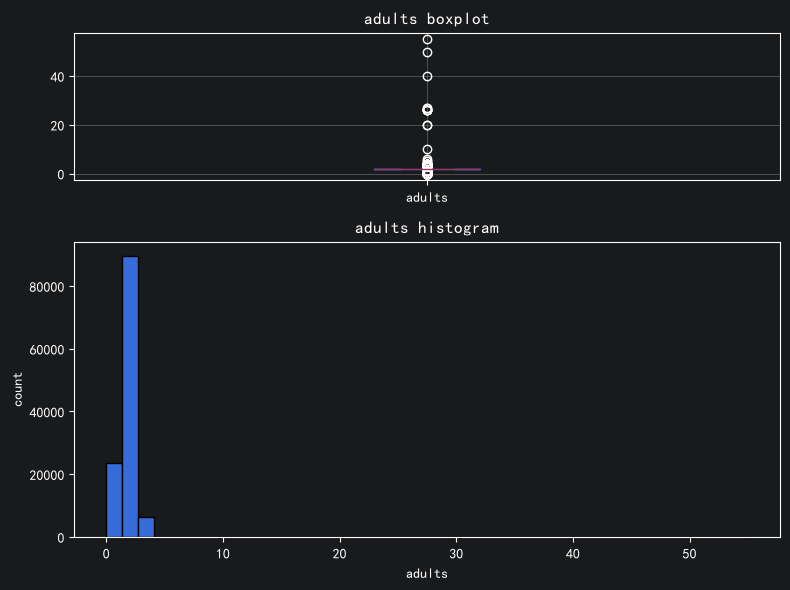

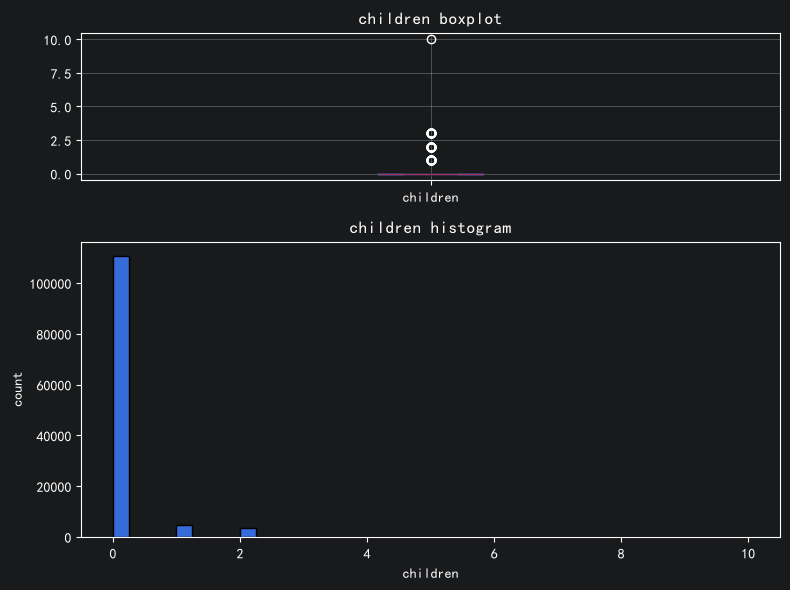

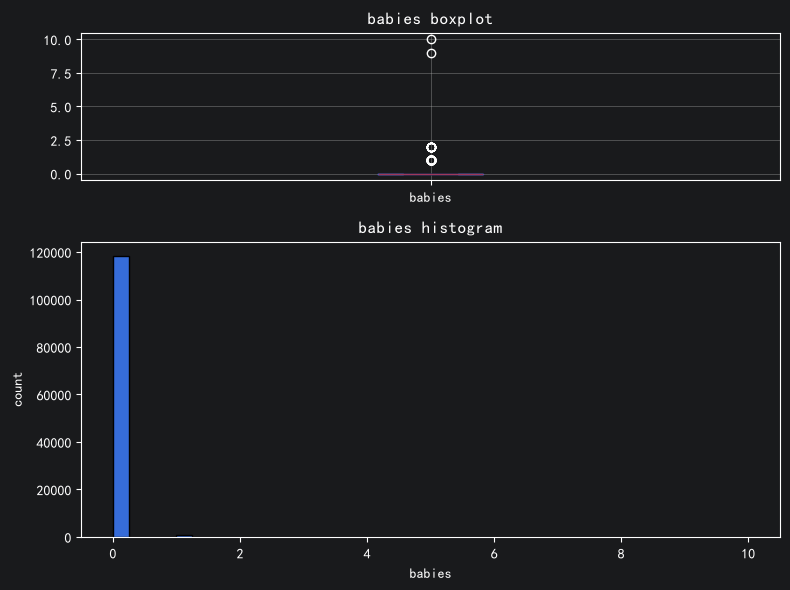

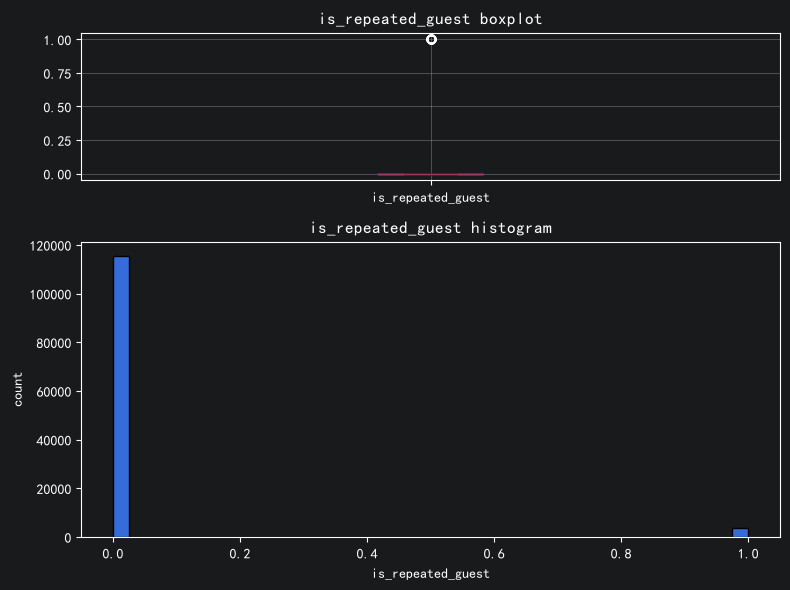

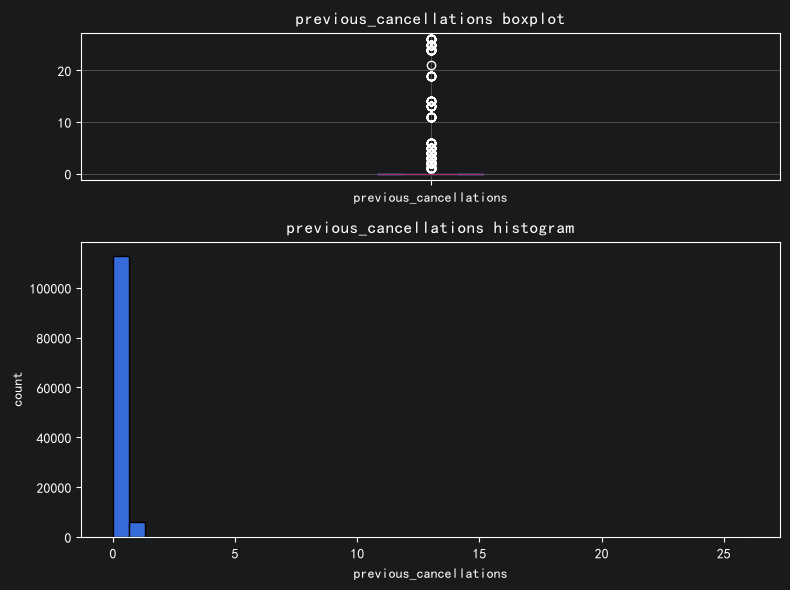

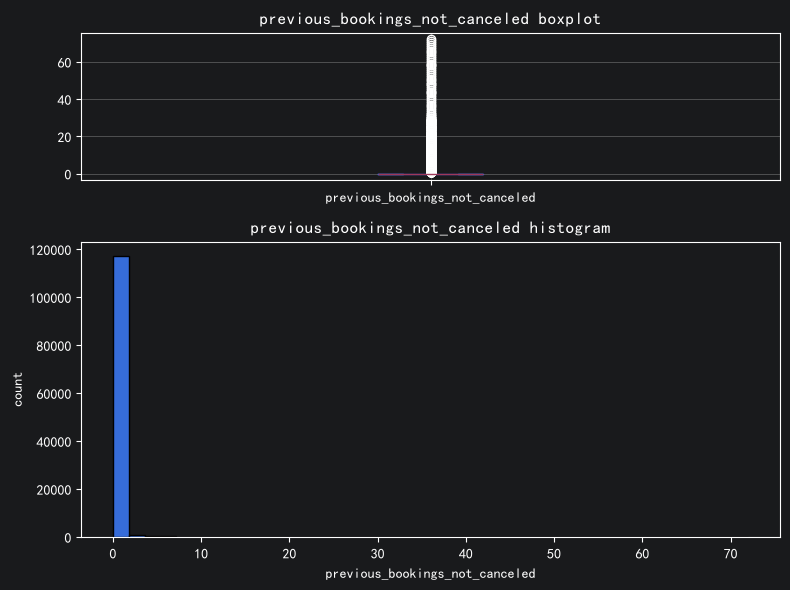

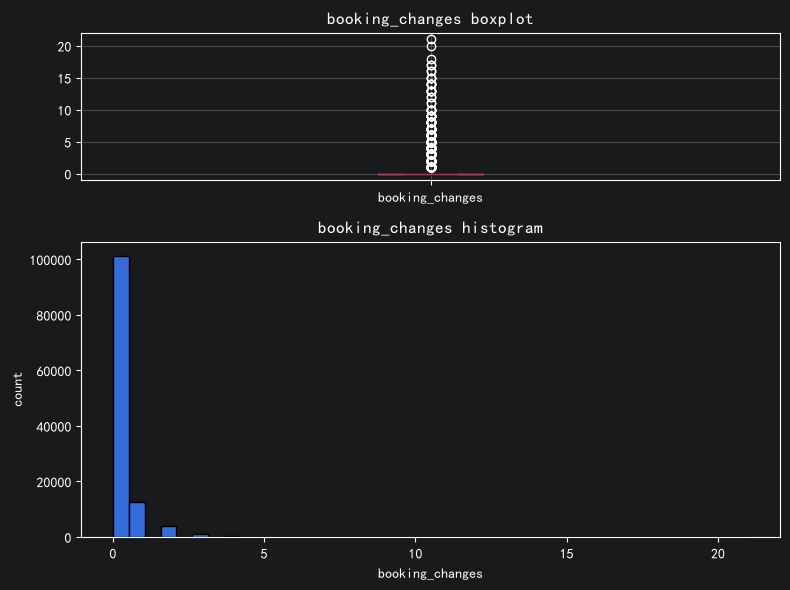

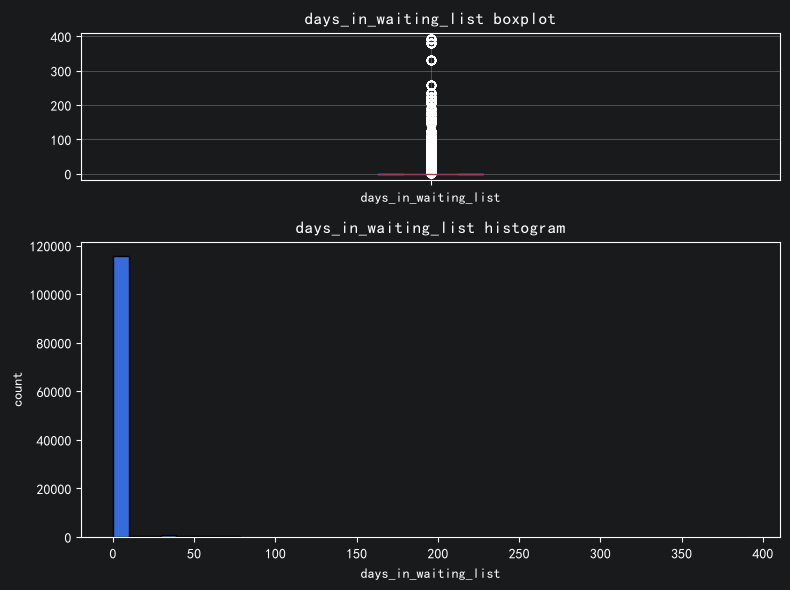

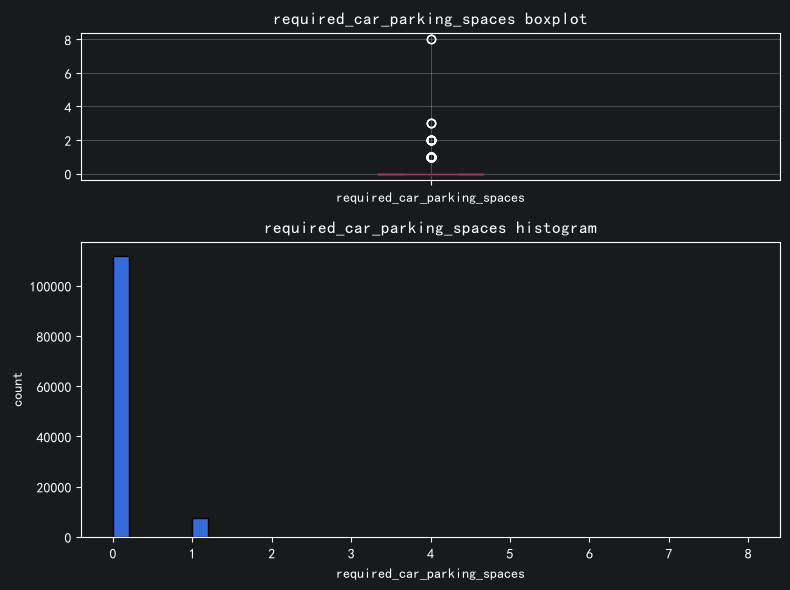

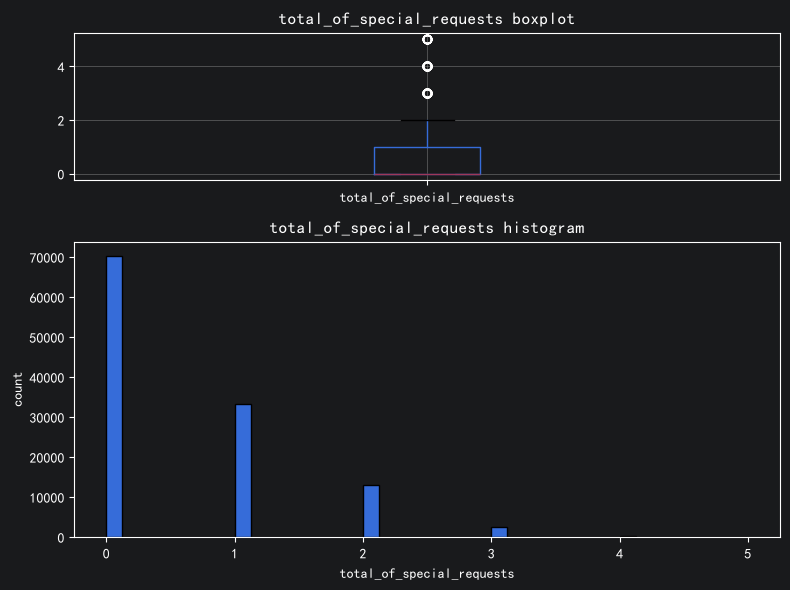

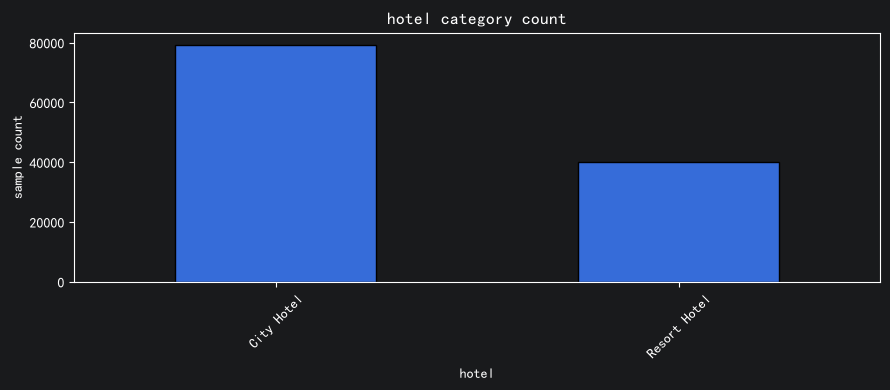

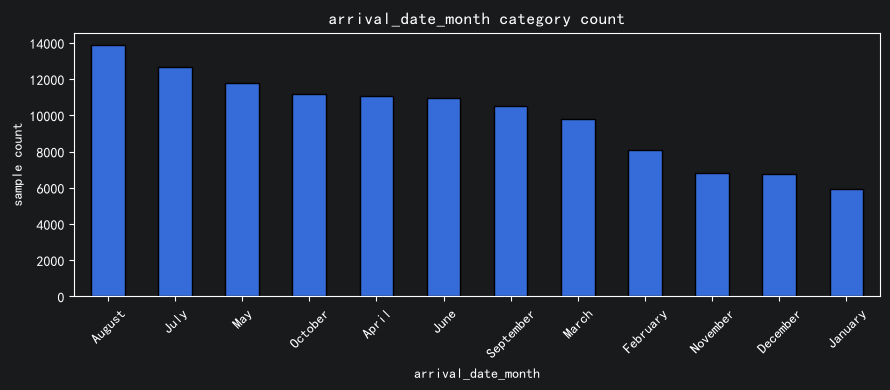

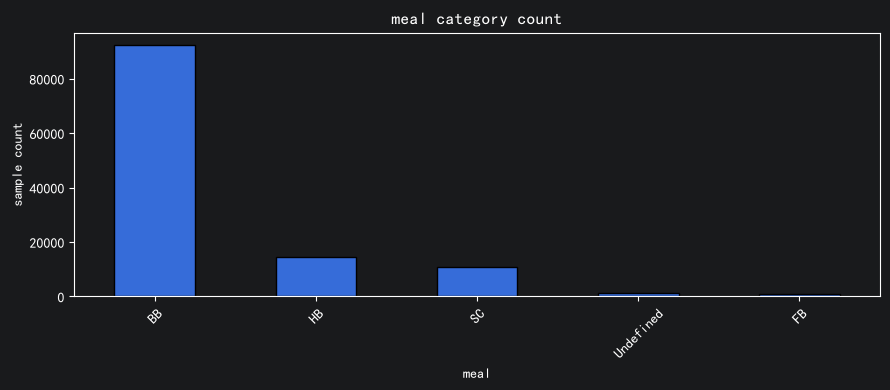

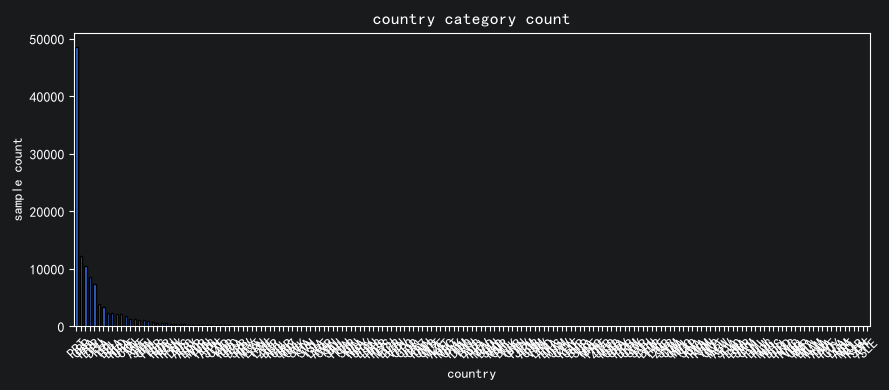

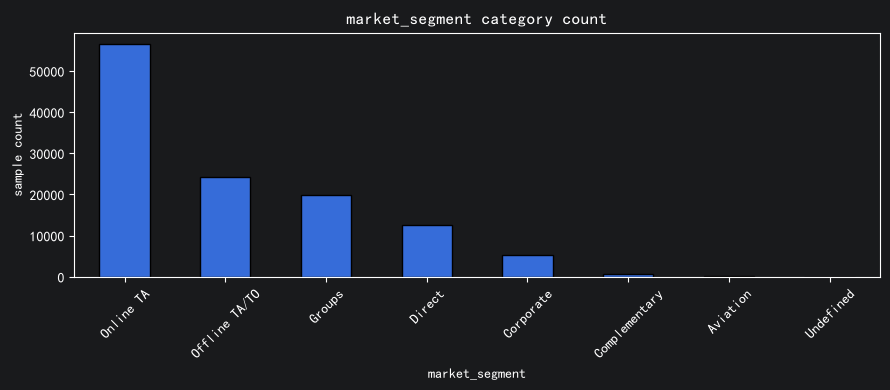

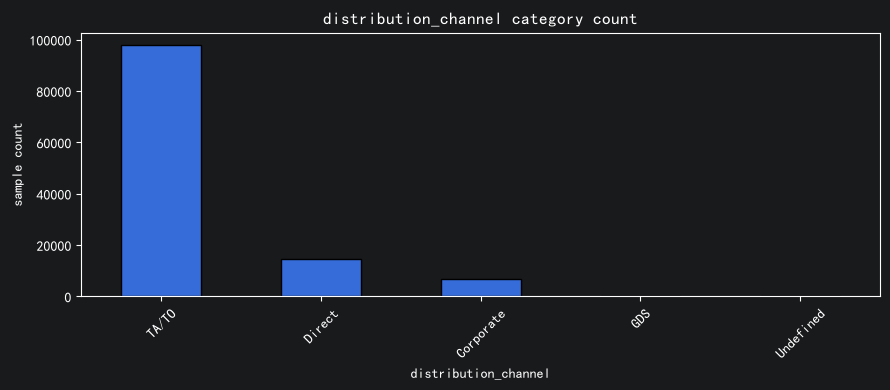

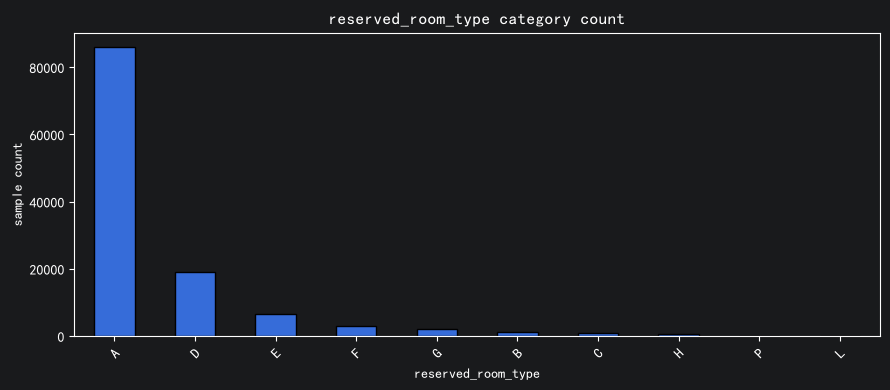

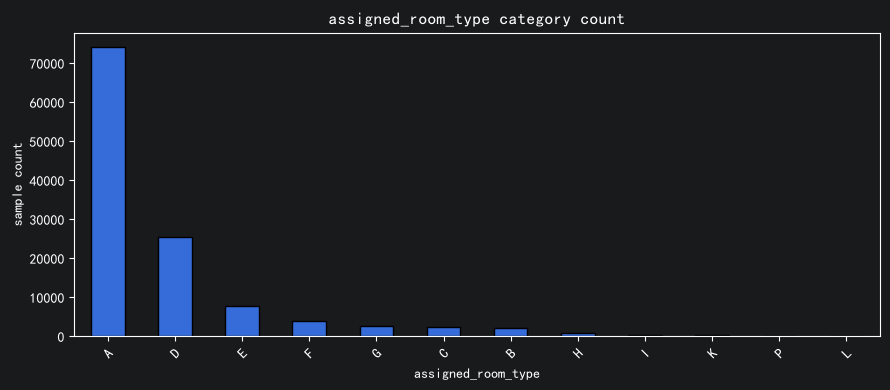

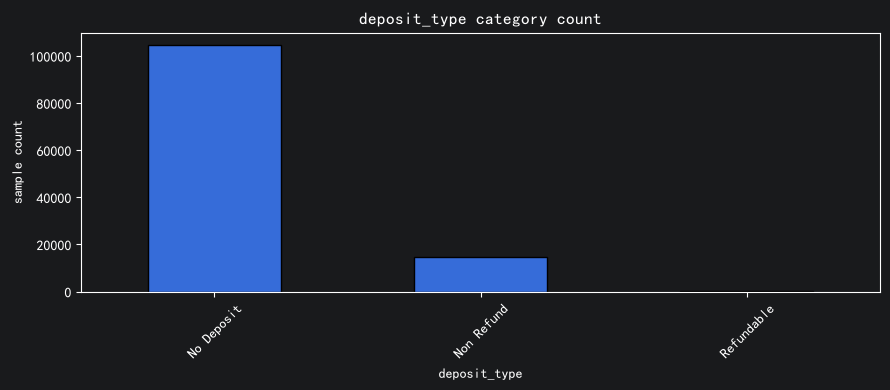

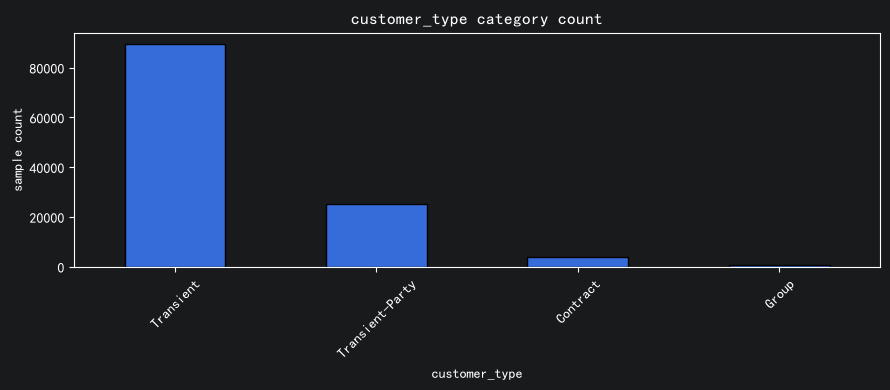

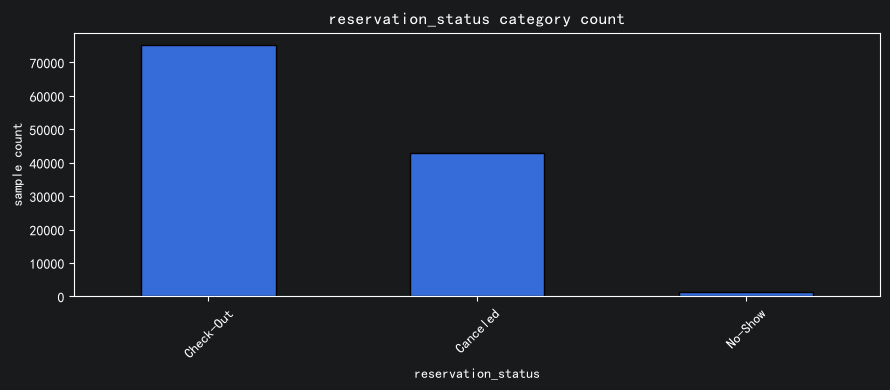

In [113]:
#三、异常值与类别分布探查
#目标：探查连续特征的极端离群样本、类别特征的取值分布；区分脏数据与业务真实样本，拟定后续清洗策略。
#1. 连续特征：绘图观察分布，对全部数值特征开展探查，识别离群样本。
# 批量绘制连续特征箱线图，用于异常探查
def plot_box_hist_numeric(df, numeric_cols):
    """批量绘制箱线图+直方图，每个特征独立画布"""
    for col in numeric_cols:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), gridspec_kw={"height_ratios": [1, 2]})
        df.boxplot(column=col, ax=ax1)
        ax1.set_title(f'{col} boxplot')
        ax1.set_xlabel('')

        ser = df[col].dropna()
        ax2.hist(ser, bins=40, edgecolor="black")
        ax2.set_title(f'{col} histogram')
        ax2.set_xlabel(col)
        ax2.set_ylabel("count")

        plt.tight_layout()
        plt.show()

all_numeric_cols = [
    'lead_time',
    'adr',
    'arrival_date_year',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'is_repeated_guest',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'required_car_parking_spaces',
    'total_of_special_requests'
]
plot_box_hist_numeric(df, all_numeric_cols)
# 非连续（类别）特征：绘制柱状图查看各类别样本数量分布；
def plot_cat_bar(df, cat_cols):
    """类别特征：柱状图查看各类别样本数量分布"""
    for col in cat_cols:
        vc = df[col].value_counts()
        fig, ax = plt.subplots(figsize=(9, 4))
        vc.plot(kind="bar", ax=ax, edgecolor="black")
        ax.set_title(f'{col} category count')
        ax.set_xlabel(col)
        ax.set_ylabel('sample count')
        ax.tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

cat_cols = [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserved_room_type",
    "assigned_room_type",
    "deposit_type",
    "customer_type",
    "reservation_status"
]
plot_cat_bar(df, cat_cols)
# 若为明显录入错误的脏类别，在后续数据清洗阶段删除该样本或标记为unknown；
# 若为业务真实存在但样本数量极少的稀有类别，根据业务价值选择保留，或合并为Other类别。
#2. 识别违背业务常识的极端样本
#3. 记录预处理方案：针对识别出的脏样本，确定后续采用截断或剔除样本的处理方式。


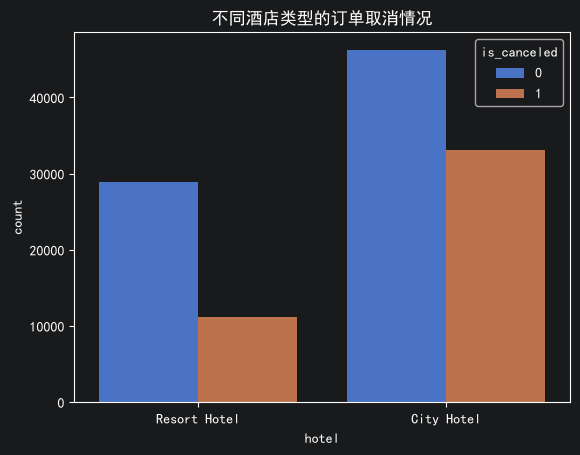

               总订单数  取消订单数       取消率
hotel                               
City Hotel    79330  33102  0.417270
Resort Hotel  40060  11122  0.277634


In [40]:
#四、单特征与目标变量关联分析
#特征多不用全部画，挑选**4~6 个业务核心特征**可视化，其余特征只简单统计
#1. 连续特征：分组对比，看「取消订单」和「未取消订单」两组的分布差异
#2. 类别特征：绘制柱状图，展示不同类别下订单取消率
#不同类型酒店的取消情况
sns.countplot(x='hotel', hue='is_canceled', data=df)
plt.title("不同酒店类型的订单取消情况") # 增加标题
plt.show()
cancel_rate = df.groupby('hotel')['is_canceled'].agg(['count','sum'])
cancel_rate.columns = ['总订单数','取消订单数']
cancel_rate['取消率'] = cancel_rate['取消订单数'] / cancel_rate['总订单数']
print(cancel_rate)

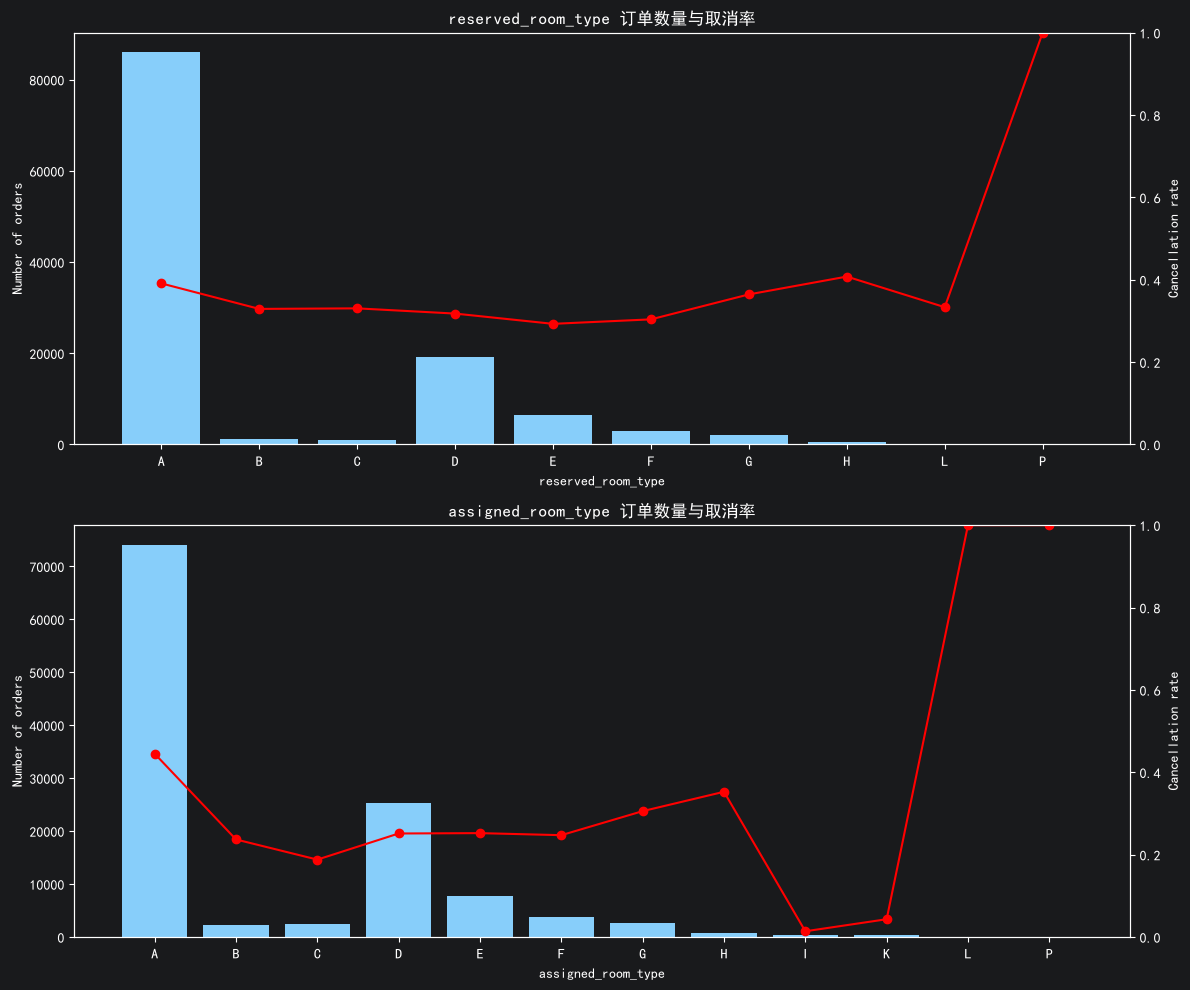


===== reserved_room_type =====
                      总订单    取消率
reserved_room_type              
P                      12  1.000
H                     601  0.408
A                   85994  0.391
G                    2094  0.364
L                       6  0.333
C                     932  0.330
B                    1118  0.329
D                   19201  0.318
F                    2897  0.304
E                    6535  0.293

===== assigned_room_type =====
                      总订单    取消率
assigned_room_type              
P                      12  1.000
L                       1  1.000
A                   74053  0.445
H                     712  0.353
G                    2553  0.306
E                    7806  0.252
D                   25322  0.251
F                    3751  0.247
B                    2163  0.237
C                    2375  0.188
K                     279  0.043
I                     363  0.014


In [45]:
#查看房间类型与取消预定的关系
plt.figure(figsize=(12, 10)) # 整张画布大小
index = 1
for room_type in ['reserved_room_type', 'assigned_room_type']:
    ax1 = plt.subplot(2, 1, index)
    index += 1
    ax2 = ax1.twinx()

    group = df.groupby(room_type)['is_canceled']
    total_cnt = group.size()       # 总订单数
    cancel_rate = group.mean()     # 取消率（is_canceled取均值）

    ax1.bar(total_cnt.index, total_cnt.values, color="#87CEFA", label="订单总数")
    ax1.set_xlabel(room_type)
    ax1.set_ylabel('Number of orders')
    ax1.tick_params(axis='x', rotation=0)

    ax2.plot(cancel_rate.index, cancel_rate.values, 'ro-', label="取消率")
    ax2.set_ylabel('Cancellation rate')
    ax2.set_ylim(0, 1) # 取消率0~1，固定y范围，对比更直观

    plt.title(f"{room_type} 订单数量与取消率")
plt.tight_layout() # 自动调整子图间距，防止文字重叠
plt.show()
for room_type in ['reserved_room_type', 'assigned_room_type']:
    room_df = df.groupby(room_type)['is_canceled'].agg(['count','mean'])
    room_df.columns = ['总订单','取消率']
    room_df = room_df.sort_values('取消率',ascending=False)
    print(f"\n===== {room_type} =====")
    print(room_df.round(3))
#订单预定和分配的房间类型多数集中在A/D/E/F四类，其中A类房型取消率高出其余三类约7-8个百分点，值得关注。

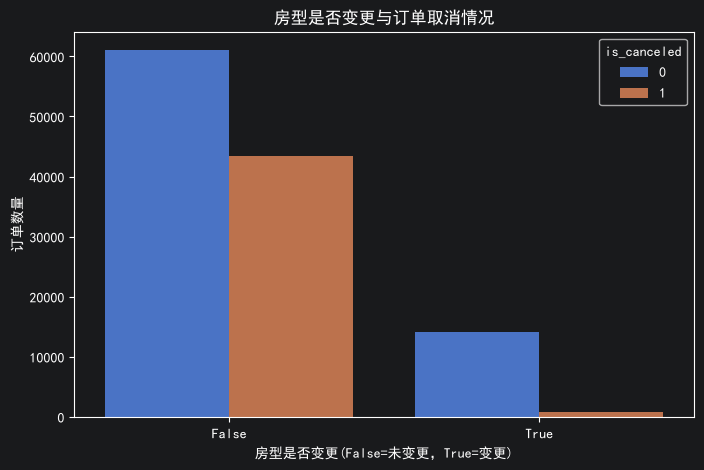

                 总订单   取消订单    取消率
room_changed                      
False         104473  43422  0.416
True           14917    802  0.054


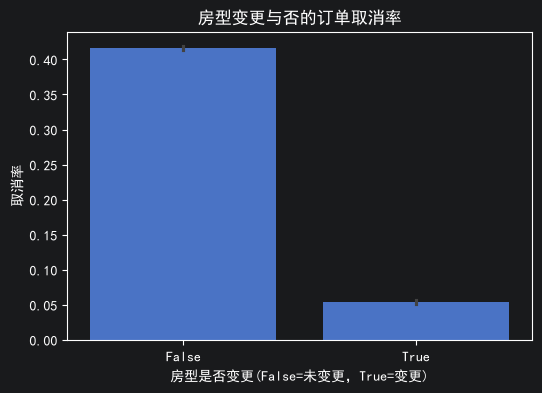

In [51]:
# 新建标记：是否发生房型变更，探索房型变更对取消的影响
df['room_changed'] = df['reserved_room_type'] != df['assigned_room_type']

# 绘制计数图
plt.figure(figsize=(8,5))
sns.countplot(x='room_changed', hue='is_canceled', data=df)
plt.title("房型是否变更与订单取消情况")
plt.xlabel("房型是否变更(False=未变更，True=变更)")
plt.ylabel("订单数量")
plt.show()
room_change_cancel = df.groupby('room_changed')['is_canceled'].agg(['count','sum','mean'])
room_change_cancel.columns = ['总订单','取消订单','取消率']
room_change_cancel['取消率'] = room_change_cancel['取消率'].round(3)
print(room_change_cancel)
plt.figure(figsize=(6,4))
sns.barplot(x='room_changed',y='is_canceled',data=df)
plt.title("房型变更与否的订单取消率")
plt.xlabel("房型是否变更(False=未变更，True=变更)")
plt.ylabel("取消率")
plt.show()
#房型变更过的客户取消预定的概率远远小于未变更过的客户，可能有以下原因：客户到达酒店后临时更改房型，多数客户会选择不取消预定，直接入住，客户自行更改房型，相对取消预定而言，这类客户更愿意更改房间类型而保证正常入住。

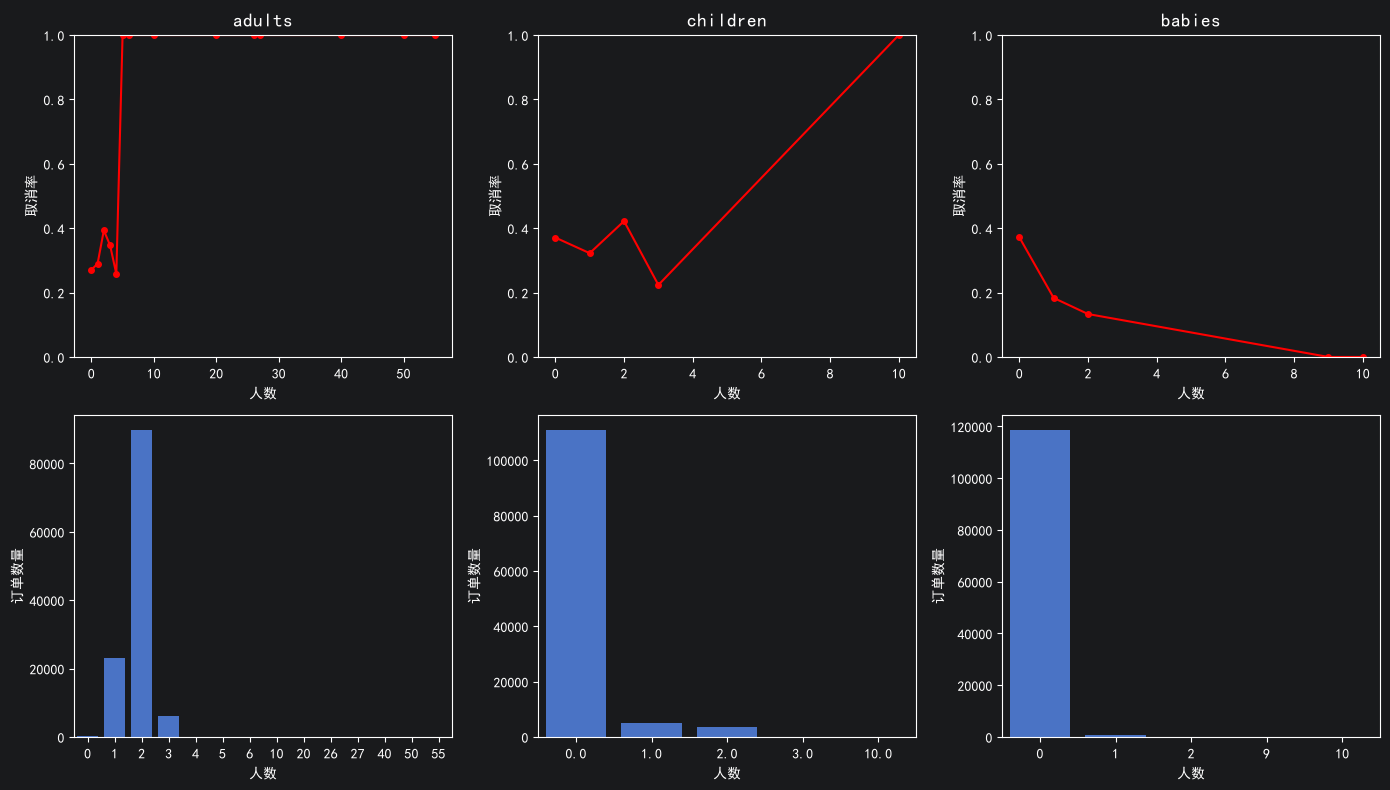

In [53]:
#客户信息分析
plt.figure(figsize=(14, 8))
index = 0
for people in ['adults', 'children', 'babies']:
    index += 1
    # 第一行：取消率折线图
    plt.subplot(2, 3, index)
    group = df.groupby(people)['is_canceled']
    cancel_rate = group.mean()
    # 过滤：只保留样本数>0的人数类别
    valid_cnt = group.size()
    valid_idx = valid_cnt[valid_cnt > 0].index
    cancel_rate = cancel_rate.loc[valid_idx]

    plt.plot(cancel_rate.index, cancel_rate.values, 'ro-', ms=4)
    plt.title(people, fontsize=14)
    plt.xlabel("人数")
    plt.ylabel("取消率")
    plt.ylim(0,1)

    # 第二行：样本数量柱状图
    plt.subplot(2, 3, index + 3)
    people_stats = df[people].value_counts().sort_index()
    people_stats = people_stats[people_stats>0]
    sns.barplot(x=people_stats.index, y=people_stats.values)
    plt.xlabel("人数")
    plt.ylabel("订单数量")

plt.tight_layout()
plt.show()
#1）多数预定订单没有儿童和婴儿入住，其中单人入住和双人入住是主要的预定人数模式；

#2）有婴儿入住时预定取消率大幅下降；

#3）超过5人以上入住的订单基本全部取消，这部分可能是刷单等异常订单，酒店需要注意。

#针对不同酒店，重点分析下列几种入住人数情况的取消率：

#单人入住：adults=1, children, babies=0

#双人入住：adults=2, children, babies=0

#家庭入住：adults>2, children, babies>0

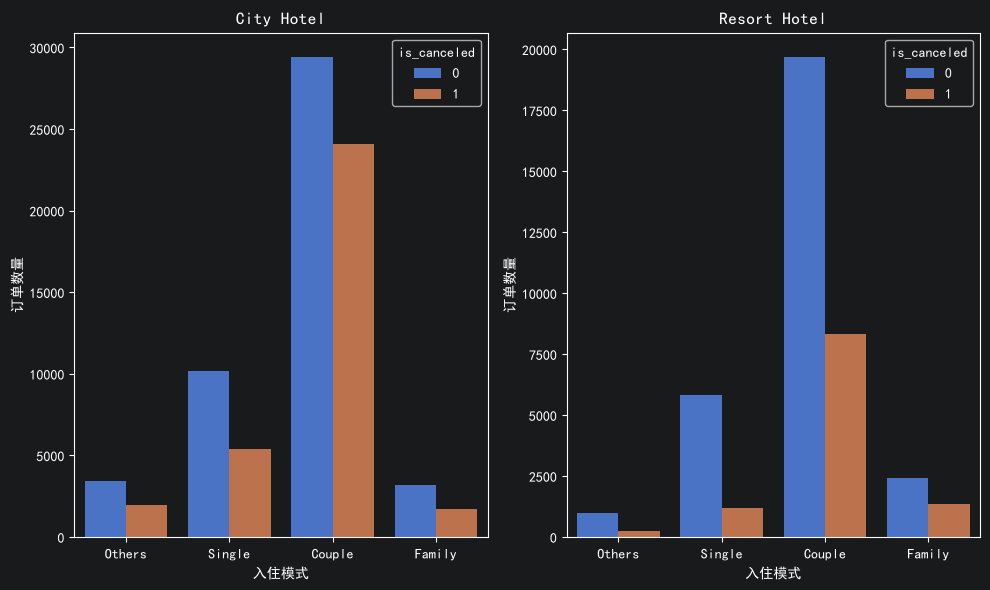

                            总订单    取消率
hotel        people_mode              
City Hotel   0             5378  0.362
             1            15564  0.345
             2            53523  0.450
             3             4865  0.349
Resort Hotel 0             1219  0.201
             1             7013  0.169
             2            28034  0.297
             3             3794  0.358


In [55]:
#定义入住模式条件
cond_single = (df.adults == 1) & (df.children == 0) & (df.babies == 0)
cond_couple = (df.adults == 2) & (df.children == 0) & (df.babies == 0)
cond_family = (df.adults >= 2) & ((df.children > 0) | (df.babies > 0))

# 优先级：家庭 > 双人 > 单人，剩下为Others
conditions = [cond_family, cond_couple, cond_single]
choices = [3, 2, 1]
df['people_mode'] = np.select(conditions, choices, default=0)

plt.figure(figsize=(10,6))
index=1
for hotel_kind in ['City Hotel','Resort Hotel']:
    plt.subplot(1,2,index)
    index+=1
    sns.countplot(x='people_mode', hue='is_canceled', data=df[df.hotel == hotel_kind])
    plt.xticks([0, 1, 2, 3], ['Others', 'Single', 'Couple', 'Family'])
    plt.title(hotel_kind)
    plt.xlabel("入住模式")
    plt.ylabel("订单数量")
plt.tight_layout()
plt.show()

# ===== 计算两种酒店下，各入住模式的取消率 =====
cancel_mode = df.groupby(['hotel','people_mode'])['is_canceled'].agg(['count','mean'])
cancel_mode.columns = ['总订单','取消率']
cancel_mode = cancel_mode.round(3)
print(cancel_mode)
#对于城市酒店，取消预定概率：双人>>单人≈家庭，应注意双人入住客户的高取消率现象，改善酒店对于双人入住客户的配套服务以降低取消率。

#对于度假酒店，取消预订概率：家庭>双人>单人，酒店可适当针对家庭客户提供相应的优惠折扣，提高家庭客户入住率。

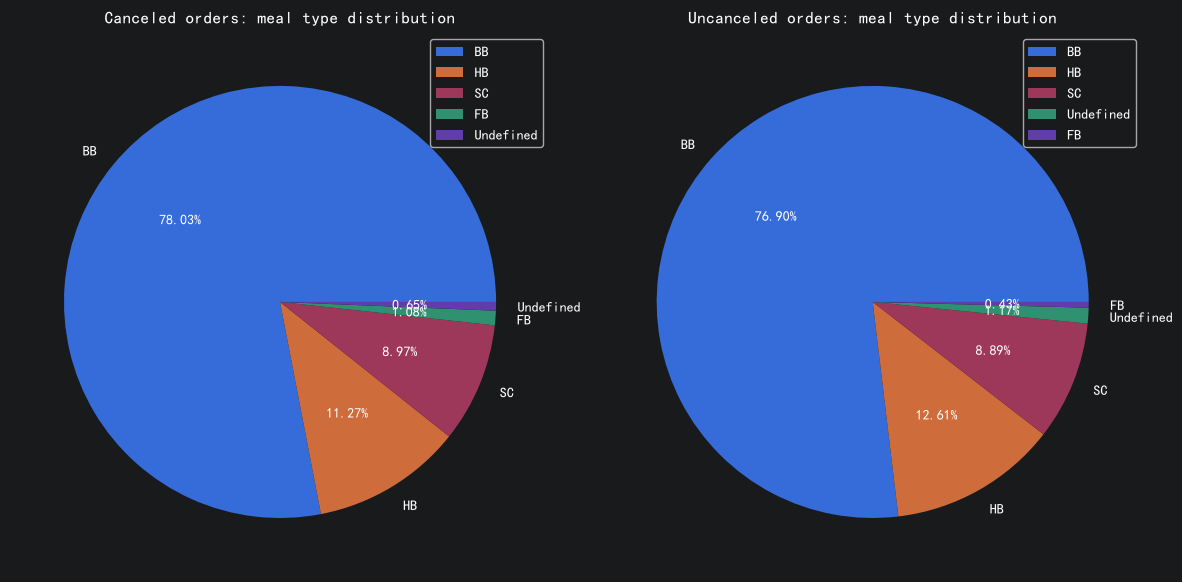

             总订单   取消订单    取消率
meal                          
BB         92310  34510  0.374
FB           798    478  0.599
HB         14463   4984  0.345
SC         10650   3966  0.372
Undefined   1169    286  0.245


In [57]:
#查看不同饮食对取消订单的影响
plt.figure(figsize=(12, 6))
# 左饼图：已取消订单的餐食分布
plt.subplot(121)
cancel_meal = df[df['is_canceled'] == 1]['meal'].value_counts()
plt.pie(cancel_meal.values, labels=cancel_meal.index, autopct="%.2f%%")
plt.legend(loc="upper right")
plt.title('Canceled orders: meal type distribution')

# 右饼图：未取消订单的餐食分布
plt.subplot(122)
uncancel_meal = df[df['is_canceled'] == 0]['meal'].value_counts()
plt.pie(uncancel_meal.values, labels=uncancel_meal.index, autopct="%.2f%%")
plt.legend(loc="upper right")
plt.title('Uncanceled orders: meal type distribution')

plt.tight_layout()
plt.show()

# 额外：计算【各餐食类型的订单取消率】（很重要，饼图没有这个信息）
meal_cancel = df.groupby('meal')['is_canceled'].agg(['count','sum','mean'])
meal_cancel.columns = ['总订单','取消订单','取消率']
meal_cancel = meal_cancel.round(3)
print(meal_cancel)
#可以看到无论是否取消预订，餐食类型之间差异不大。

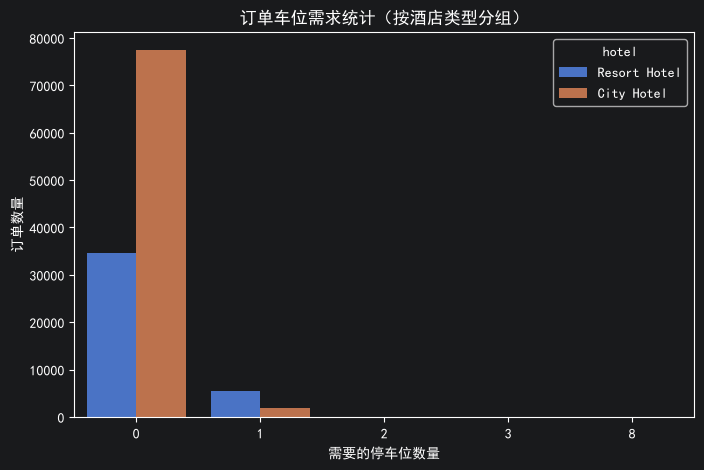

                                总订单   取消订单    取消率
required_car_parking_spaces                      
0                            111974  44224  0.395
1                              7383      0  0.000
2                                28      0  0.000
3                                 3      0  0.000
8                                 2      0  0.000


In [59]:
#车位需求对取消订单的影响
plt.figure(figsize=(8,5))
sns.countplot(x='required_car_parking_spaces', hue='hotel', data=df)
plt.title("订单车位需求统计（按酒店类型分组）")
plt.xlabel("需要的停车位数量")
plt.ylabel("订单数量")
plt.show()
# 按车位需求分组，计算取消率
parking_cancel = df.groupby('required_car_parking_spaces')['is_canceled'].agg(['count','sum','mean'])
parking_cancel.columns = ['总订单','取消订单','取消率']
parking_cancel = parking_cancel.round(3)
parking_cancel = parking_cancel[parking_cancel['总订单']>0] # 过滤空类别
print(parking_cancel)
#从分析可以看出停车位的需求对取消订单几乎没有影响，取消订单的都是不需要车位的顾客

订单量前20国家的订单占全部订单比例：93.83%


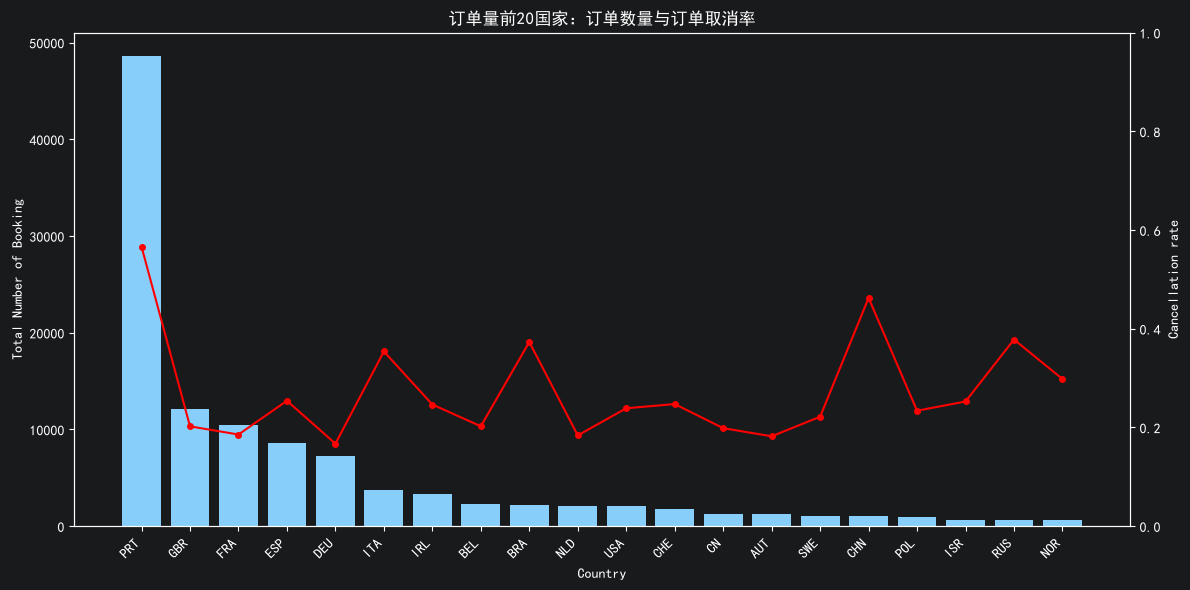

           总订单    取消率
country              
PRT      48590  0.566
GBR      12129  0.202
FRA      10415  0.186
ESP       8568  0.254
DEU       7287  0.167
ITA       3766  0.354
IRL       3375  0.247
BEL       2342  0.202
BRA       2224  0.373
NLD       2104  0.184
USA       2097  0.239
CHE       1730  0.247
CN        1279  0.199
AUT       1263  0.182
SWE       1024  0.222
CHN        999  0.462
POL        919  0.234
ISR        669  0.253
RUS        632  0.378
NOR        607  0.298


In [61]:
# 选取订单数量前20的国家
countries_20 = list(
    df.groupby('country').size().sort_values(ascending=False).head(20).index
)
# 计算前20国订单占全部订单的比例
ratio = df[df.country.isin(countries_20)].shape[0] / df.shape[0]
print(f"订单量前20国家的订单占全部订单比例：{ratio:.2%}")

# 筛选top20国家子集
df_top20 = df[df['country'].isin(countries_20)]
# 分组统计
group_cnt = df_top20.groupby('country').size().sort_values(ascending=False)
group_cancel_rate = df_top20.groupby('country')['is_canceled'].mean().loc[group_cnt.index]

fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

ax1.bar(range(20), group_cnt.values, color="#87CEFA")
ax1.set_xlabel('Country')
ax1.set_ylabel('Total Number of Booking')
ax1.set_xticks(range(20))
ax1.set_xticklabels(group_cnt.index, rotation=45, ha='right') # 旋转国家标签，防止重叠

ax2.plot(range(20), group_cancel_rate.values, 'ro-', ms=4)
ax2.set_ylabel('Cancellation rate')
ax2.set_ylim(0,1) # 取消率固定0~1

plt.title("订单量前20国家：订单数量与订单取消率")
plt.tight_layout()
plt.show()

# 打印表格：前20国家的订单总数、取消率
country_cancel = df_top20.groupby('country')['is_canceled'].agg(['count','mean'])
country_cancel.columns = ['总订单','取消率']
country_cancel = country_cancel.sort_values('总订单', ascending=False).round(3)
print(country_cancel)
#统计可知，前20名国家/地区数据量占据全部数据的94%，客户主要来自葡萄牙，英国，法国，西班牙等欧洲国家，不同国家之间预定取消率的差距非常显著，取消率较高的国家有葡萄牙、意大利、巴西、中国、俄罗斯，以发展中国家为主。

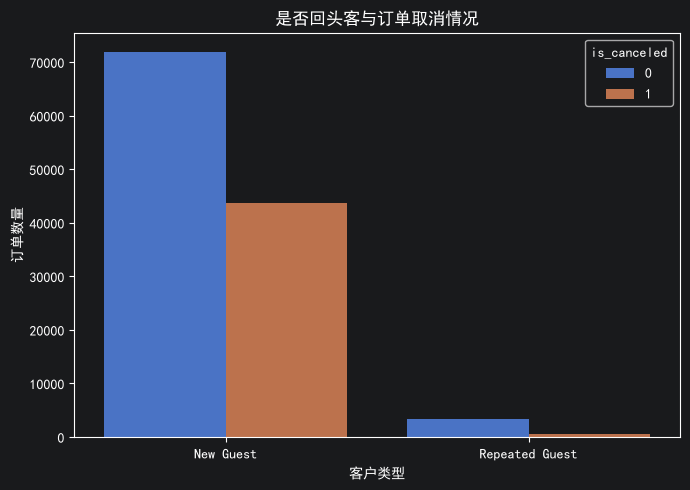

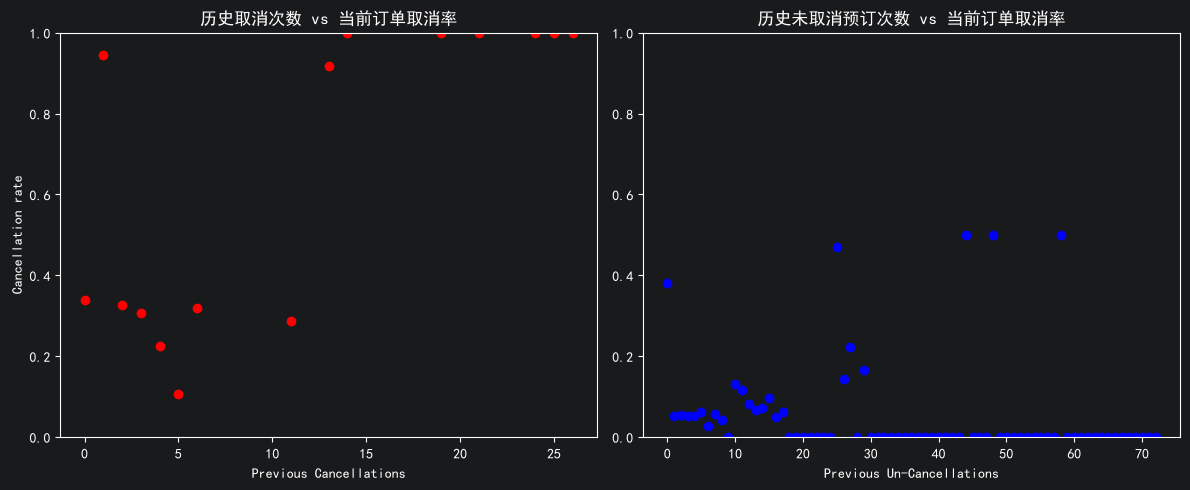

===== 是否回头客 取消率 =====
        总订单    取消率
新客户  115580  0.378
回头客    3810  0.145

===== 历史取消次数 取消率 =====
                           总订单    取消率
previous_cancellations               
0                       112906  0.339
1                         6051  0.944
2                          116  0.328
3                           65  0.308
4                           31  0.226
5                           19  0.105
6                           22  0.318
11                          35  0.286
13                          12  0.917
14                          14  1.000
19                          19  1.000
21                           1  1.000
24                          48  1.000
25                          25  1.000
26                          26  1.000

===== 历史未取消次数 取消率 =====
                                   总订单    取消率
previous_bookings_not_canceled               
0                               115770  0.380
1                                 1542  0.051
2                                  580  0.

In [63]:
#历史取消次数和取消订单的关系
# ========== 图1：是否回头客与订单取消 ==========
plt.figure(figsize=(7,5))
tick_label = ['New Guest', 'Repeated Guest']
sns.countplot(x='is_repeated_guest', hue='is_canceled', data=df)
plt.xticks([0, 1], tick_label)
plt.title("是否回头客与订单取消情况")
plt.xlabel("客户类型")
plt.ylabel("订单数量")
plt.tight_layout()
plt.show()

# ========== 图2：历史取消次数、历史未取消次数 双图 ==========
plt.figure(figsize=(12, 5))
# 左子图：历史取消次数
plt.subplot(121)
group_cancel = df.groupby('previous_cancellations')['is_canceled']
valid = group_cancel.size()
valid_idx = valid[valid>0].index
rate_cancel = group_cancel.mean().loc[valid_idx]
plt.plot(rate_cancel.index, rate_cancel.values, 'ro')
plt.xlabel('Previous Cancellations')
plt.ylabel('Cancellation rate')
plt.title("历史取消次数 vs 当前订单取消率")
plt.ylim(0,1)

# 右子图：历史未取消预订次数
plt.subplot(122)
group_notcancel = df.groupby('previous_bookings_not_canceled')['is_canceled']
valid2 = group_notcancel.size()
valid_idx2 = valid2[valid2>0].index
rate_notcancel = group_notcancel.mean().loc[valid_idx2]
plt.plot(rate_notcancel.index, rate_notcancel.values, 'bo')
plt.xlabel('Previous Un-Cancellations')
plt.title("历史未取消预订次数 vs 当前订单取消率")
plt.ylim(0,1)

plt.tight_layout()
plt.show()

# ========== 配套统计表格 ==========
print("===== 是否回头客 取消率 =====")
repeat_stat = df.groupby('is_repeated_guest')['is_canceled'].agg(['count','mean'])
repeat_stat.columns = ['总订单','取消率']
repeat_stat.index = ['新客户','回头客']
print(repeat_stat.round(3))

print("\n===== 历史取消次数 取消率 =====")
prev_cancel_stat = df.groupby('previous_cancellations')['is_canceled'].agg(['count','mean'])
prev_cancel_stat.columns = ['总订单','取消率']
prev_cancel_stat = prev_cancel_stat[prev_cancel_stat['总订单']>0].round(3)
print(prev_cancel_stat)

print("\n===== 历史未取消次数 取消率 =====")
prev_notcancel_stat = df.groupby('previous_bookings_not_canceled')['is_canceled'].agg(['count','mean'])
prev_notcancel_stat.columns = ['总订单','取消率']
prev_notcancel_stat = prev_notcancel_stat[prev_notcancel_stat['总订单']>0].round(3)
print(prev_notcancel_stat)
#从图一可以看出样本中新客户占绝大多数，回头客订单数量很少；回头客的订单取消率显著低于首次预订的新客户，老客户预订稳定性更强。
#从图二可以看出随着客户历史取消次数增加，本次订单取消概率整体呈现上升趋势；有多次取消记录的客户，再次退订风险明显更高。
#从图三可以看出客户历史成功预订次数越多，本次订单取消率整体越低。多次成功入住的忠实客户，预订稳定性更高。
#结论回头客的订单取消率显著低于新客户。客户历史行为对当前退订风险有较强影响：历史取消次数越多，本次预订越容易取消；历史成功入住记录越多，本次退订概率越低。该特征具备较强预测价值，可作为建模特征。

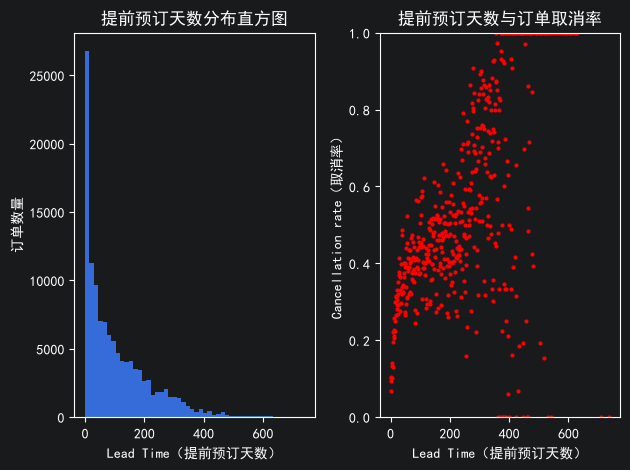

                 总订单    取消率
lead_time_bin              
0-7天           13401  0.110
8-30天          18960  0.279
31-90天         29553  0.377
91-180天        26439  0.447
>180天          22578  0.557


In [65]:
#客户信息与取消订单关系
# 左子图：提前预订天数分布直方图
plt.subplot(121)
plt.hist(df['lead_time'], bins=50)
plt.xlabel('Lead Time（提前预订天数）')
plt.ylabel('订单数量')
plt.title("提前预订天数分布直方图")

# 右子图：提前预订天数与取消率
plt.subplot(122)
group = df.groupby('lead_time')['is_canceled']
cnt = group.size()
rate = group.mean()
# 过滤：仅保留样本数>0的天数
valid_idx = cnt[cnt>0].index
rate_valid = rate.loc[valid_idx]

plt.plot(rate_valid.index, rate_valid.values, 'ro', markersize=2)
plt.xlabel('Lead Time（提前预订天数）')
plt.ylabel('Cancellation rate（取消率）')
plt.ylim(0,1)
plt.title("提前预订天数与订单取消率")

plt.tight_layout()
plt.show()

# 可选：按区间分组统计（更适合报告）
# 划分提前预订区间
df['lead_time_bin'] = pd.cut(df['lead_time'], bins=[0,7,30,90,180, 400], labels=['0-7天','8-30天','31-90天','91-180天','>180天'])
lead_bin_cancel = df.groupby('lead_time_bin')['is_canceled'].agg(['count','mean'])
lead_bin_cancel.columns = ['总订单','取消率']
lead_bin_cancel = lead_bin_cancel.round(3)
print(lead_bin_cancel)
#从分布来看，大多数订单的提前预订天数集中在短期区间，远期预订订单数量较少。从取消率来看，提前预订天数与退订风险存在明显正相关：预订距离入住时间越远，订单取消概率越高。临近入住的预订客户计划稳定性更高，取消风险更低。

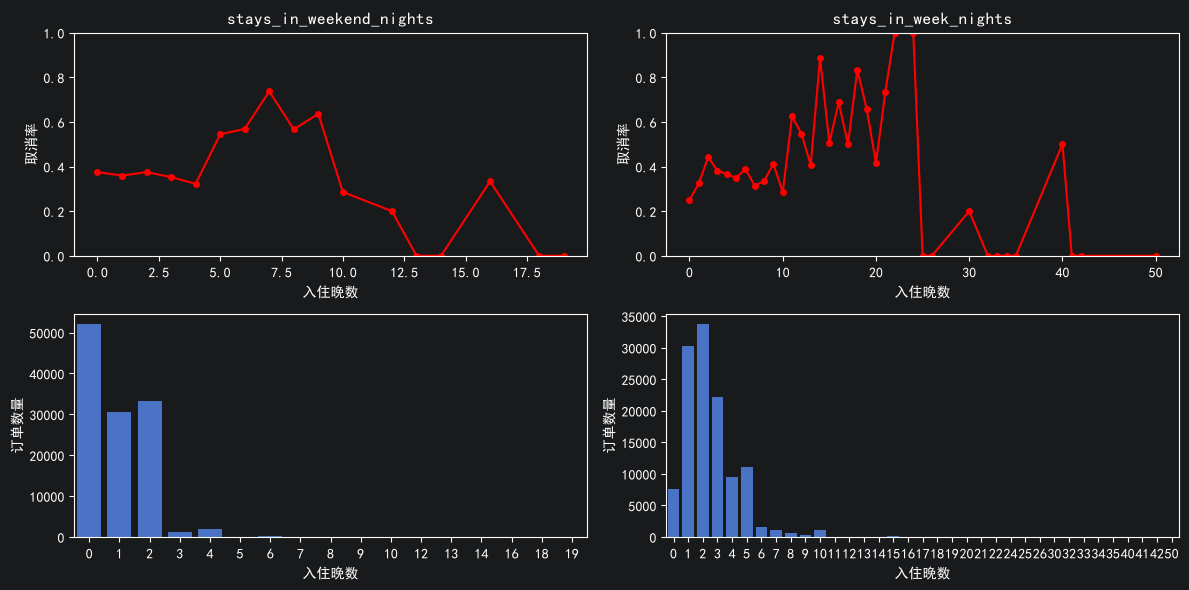


===== stays_in_weekend_nights =====
                           总订单    取消率
stays_in_weekend_nights              
0                        51998  0.375
1                        30626  0.359
2                        33308  0.375
3                         1259  0.353
4                         1855  0.322
5                           79  0.544
6                          153  0.569
7                           19  0.737
8                           60  0.567
9                           11  0.636
10                           7  0.286
12                           5  0.200
13                           3  0.000
14                           2  0.000
16                           3  0.333
18                           1  0.000
19                           1  0.000

===== stays_in_week_nights =====
                        总订单    取消率
stays_in_week_nights              
0                      7645  0.250
1                     30310  0.324
2                     33684  0.442
3                     22258  0.3

In [67]:
#周末入住晚数和工作日入住晚数对取消订单的影响
plt.figure(figsize=(12, 6))
index = 0
for night in ['stays_in_weekend_nights', 'stays_in_week_nights']:
    index += 1
    # 第一行：取消率折线
    plt.subplot(2, 2, index)
    group = df.groupby(night)['is_canceled']
    cnt = group.size()
    valid_idx = cnt[cnt > 0].index
    rate = group.mean().loc[valid_idx]
    plt.plot(rate.index, rate.values, 'ro-', ms=4)
    plt.title(night)
    plt.xlabel("入住晚数")
    plt.ylabel("取消率")
    plt.ylim(0, 1)

    # 第二行：样本数量柱状图
    plt.subplot(2, 2, index + 2)
    night_stats = df[night].value_counts().sort_index()
    night_stats = night_stats[night_stats > 0]
    sns.barplot(x=night_stats.index, y=night_stats.values)
    plt.xlabel("入住晚数")
    plt.ylabel("订单数量")

plt.tight_layout()
plt.show()

# 计算对应取消率统计表
for night in ['stays_in_weekend_nights', 'stays_in_week_nights']:
    stat_df = df.groupby(night)['is_canceled'].agg(['count','mean'])
    stat_df.columns = ['总订单','取消率']
    stat_df = stat_df[stat_df['总订单']>0].round(3)
    print(f"\n===== {night} =====")
    print(stat_df)
    #从图标中可以看出无论是周末还是工作日，晚数较少取消的概率相对较小

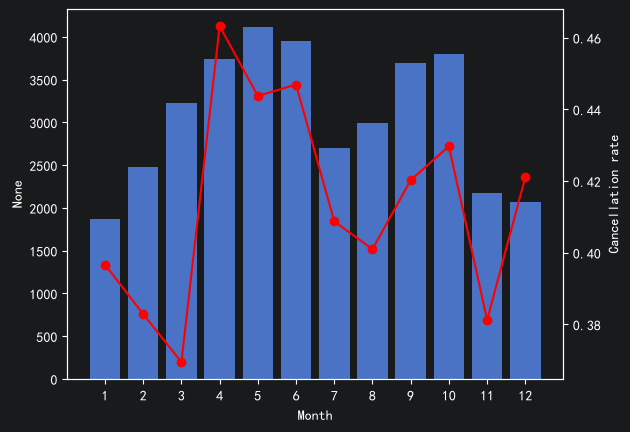

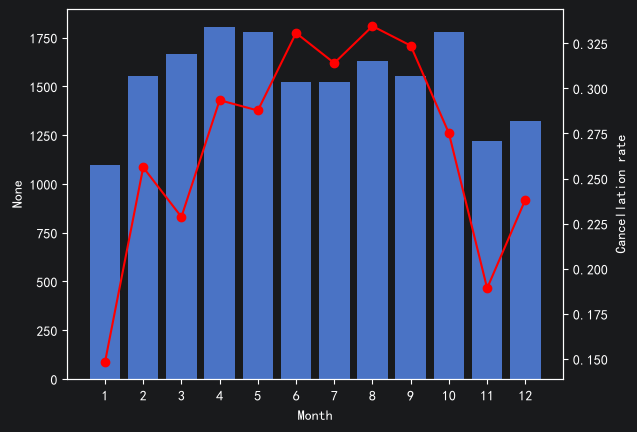

In [73]:
#不同月份取消订单的情况
ordered_months = [
    "January", "February", "March", "April", "May", "June", "July", "August",
    "September", "October", "November", "December"
]
for hotel in ['City Hotel','Resort Hotel']:
    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()
    data_hotel=df[df.hotel==hotel]
    monthly = data_hotel.groupby('arrival_date_month').size()
    monthly /= 2
    monthly.loc[['July', 'August']] = monthly.loc[['July', 'August']] * 2 / 3
    # 修复：增加 x=  y= 关键字
    sns.barplot(x=list(range(1, 13)), y=monthly[ordered_months], ax=ax1)
    ax2.plot(
        range(12), data_hotel.groupby('arrival_date_month')
        ['is_canceled'].mean()[ordered_months].values, 'ro-')
    ax1.set_xlabel('Month')
    ax2.set_ylabel('Cancellation rate')
    #结论：1）预定量上，城市酒店7/8月出现大幅下滑，同期度假酒店变化较小，整体而言，度假酒店月度客流量变化较小；

     #2）取消率上，两家酒店冬季取消率相对较低，城市酒店夏季取消率降低，度假酒店却处于高峰。

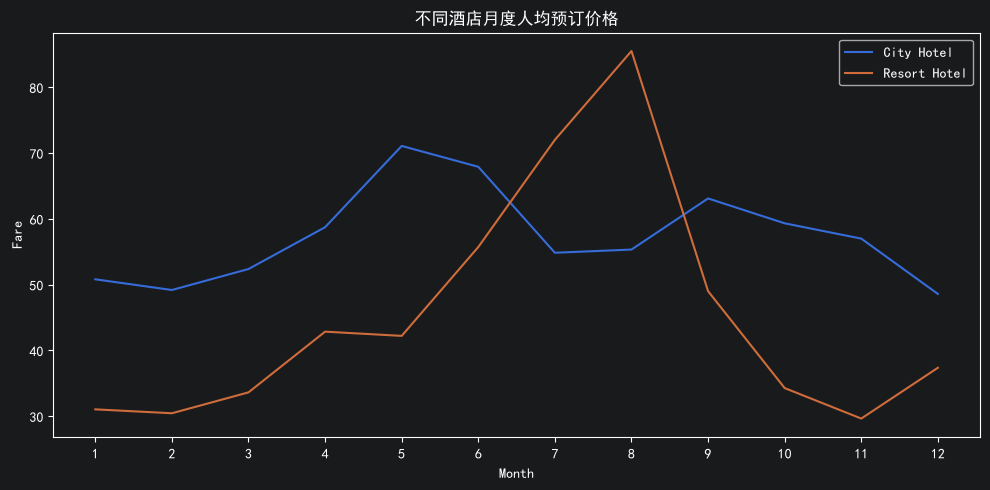

=====城市酒店月度人均价格=====
arrival_date_month
January      50.80
February     49.17
March        52.36
April        58.71
May          71.07
June         67.90
July         54.83
August       55.32
September    63.09
October      59.31
November     56.98
December     48.58
Name: adr_per_person, dtype: float64

=====度假酒店月度人均价格=====
arrival_date_month
January      31.03
February     30.44
March        33.62
April        42.84
May          42.20
June         55.70
July         72.00
August       85.49
September    48.99
October      34.27
November     29.63
December     37.35
Name: adr_per_person, dtype: float64


In [75]:
#人均价格对取消订单的影响
# 不同酒店人均价格波动
# 人均价格(不考虑babies)
df['adr_per_person'] = df['adr'] / (df['adults'] + df['children'])
# 防护：剔除分母为0的异常样本（adults+children=0，避免除零报错）
df = df[ (df['adults'] + df['children']) > 0 ]

ordered_months = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

plt.figure(figsize=(10,5))
plt.plot(df[df.hotel == 'City Hotel'].groupby('arrival_date_month')
         ['adr_per_person'].mean()[ordered_months],
         label='City Hotel')
plt.plot(df[df.hotel == 'Resort Hotel'].groupby('arrival_date_month')
         ['adr_per_person'].mean()[ordered_months],
         label='Resort Hotel')
plt.xlabel('Month')
plt.ylabel('Fare')
plt.xticks(np.arange(12), range(1, 13))
plt.legend()
plt.title("不同酒店月度人均预订价格")
plt.tight_layout()
plt.show()

# 输出统计表
print("=====城市酒店月度人均价格=====")
city_price = df[df.hotel == 'City Hotel'].groupby('arrival_date_month')['adr_per_person'].mean().reindex(ordered_months)
print(city_price.round(2))
print("\n=====度假酒店月度人均价格=====")
resort_price = df[df.hotel == 'Resort Hotel'].groupby('arrival_date_month')['adr_per_person'].mean().reindex(ordered_months)
print(resort_price.round(2))
#两种酒店客房价格趋势主要差异在于7-8月，此时期城市酒店价格小幅下跌，度假酒店价格却急速上涨，一度超过城市酒店。结合预定量和取消量分析，7-8月度假酒店客流减少，取消率大幅上升，经营者应考虑调整价格策略以增加营收。对于用户而言，应考虑避免8月预定度假酒店，此时酒店价格处于高位，而9月价格便会下跌近一半，气候/环境差异不大，是入住的好时期。

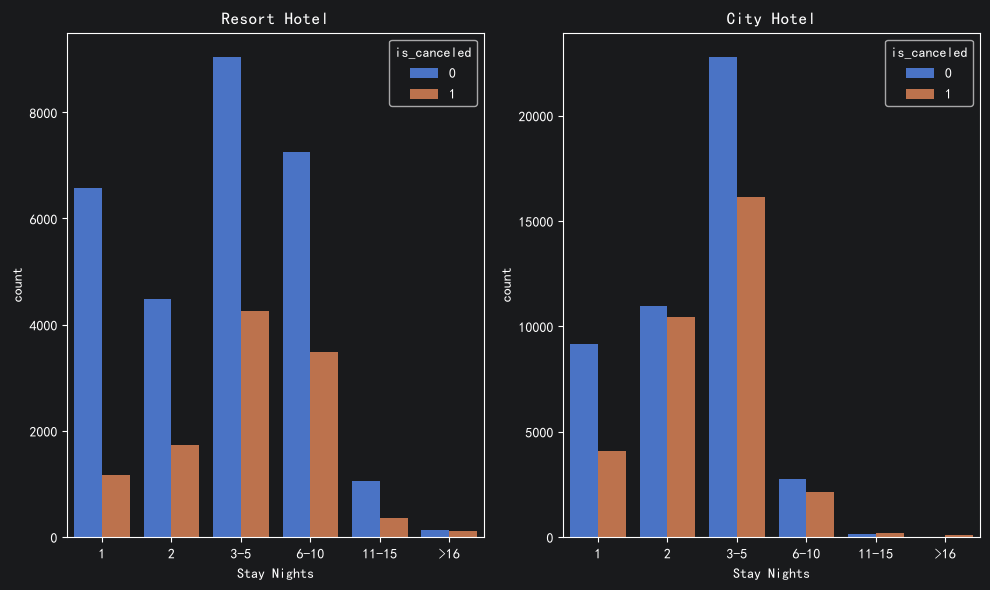

=====度假酒店 入住时长分桶取消率=====
                   总订单    取消率
stay_nights_bin              
1                 7747  0.151
2                 6217  0.278
3-5              13305  0.320
6-10             10733  0.324
11-15             1420  0.256
>16                244  0.471

=====城市酒店 入住时长分桶取消率=====
                   总订单    取消率
stay_nights_bin              
1                13257  0.309
2                21413  0.487
3-5              38903  0.414
6-10              4890  0.436
11-15              319  0.621
>16                113  0.814


In [77]:
# 预定入住时长对取消预定的影响
df['stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
# 分布过散，进行数据分桶
bin = [0, 1, 2, 5, 10, 15, np.inf]
df['stay_nights_bin'] = pd.cut(df['stay_nights'], bin,
                                 labels=['1', '2', '3-5', '6-10', '11-15', '>16'])

plt.figure(figsize=(10,6))
plt.subplot(121)
sns.countplot(x='stay_nights_bin', hue='is_canceled',
              data=df[df['hotel'] == 'Resort Hotel'])
plt.xlabel('Stay Nights')
plt.title('Resort Hotel')

plt.subplot(122)
sns.countplot(x='stay_nights_bin', hue='is_canceled',
              data=df[df['hotel'] == 'City Hotel'])
plt.xlabel('Stay Nights')
plt.title('City Hotel')

plt.tight_layout()
plt.show()

# 配套统计：各分桶的取消率
print("=====度假酒店 入住时长分桶取消率=====")
resort_bin = df[df['hotel']=='Resort Hotel'].groupby('stay_nights_bin')['is_canceled'].agg(['count','mean'])
resort_bin.columns = ['总订单','取消率']
print(resort_bin.round(3))

print("\n=====城市酒店 入住时长分桶取消率=====")
city_bin = df[df['hotel']=='City Hotel'].groupby('stay_nights_bin')['is_canceled'].agg(['count','mean'])
city_bin.columns = ['总订单','取消率']
print(city_bin.round(3))
#结论：1）度假酒店客户入住时长集中在1-10晚，其中入住1晚的客户取消概率最低；

#2）城市酒店客户入住时长多在5晚以内，其中入住2晚的客户取消概率最高；

#3）整体而言，度假酒店客户平均入住天数明显高于城市酒店，可以考虑推出长租优惠方案吸引顾客

Text(0, 0.5, 'Rate')

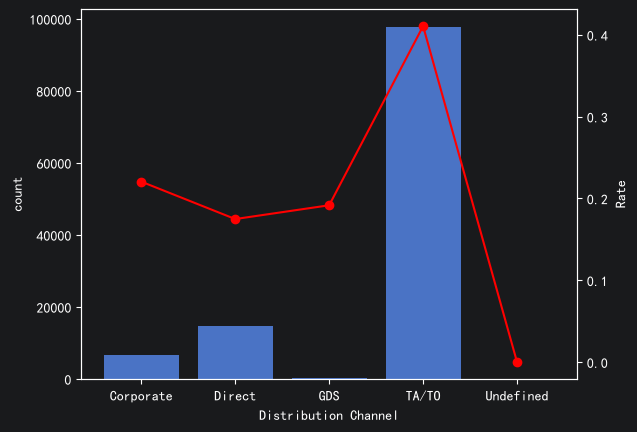

In [79]:
# 预定渠道对取消率的影响
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
sns.countplot(
    x=df['distribution_channel'],
    order=df.groupby('distribution_channel')['is_canceled'].mean().index,
    ax=ax1)
ax1.set_xlabel('Distribution Channel')
ax2.plot(df.groupby('distribution_channel')['is_canceled'].mean(), 'ro-')
ax2.set_ylabel('Rate')
#1）预定主要来自于旅行社(TA/TO)，个人直接预定(Direct)和团体预定(Group)；

#2）旅行社取消预定的概率远大于其他渠道，可能是由于旅行社出于盈利考虑会取消利润较低的订单。

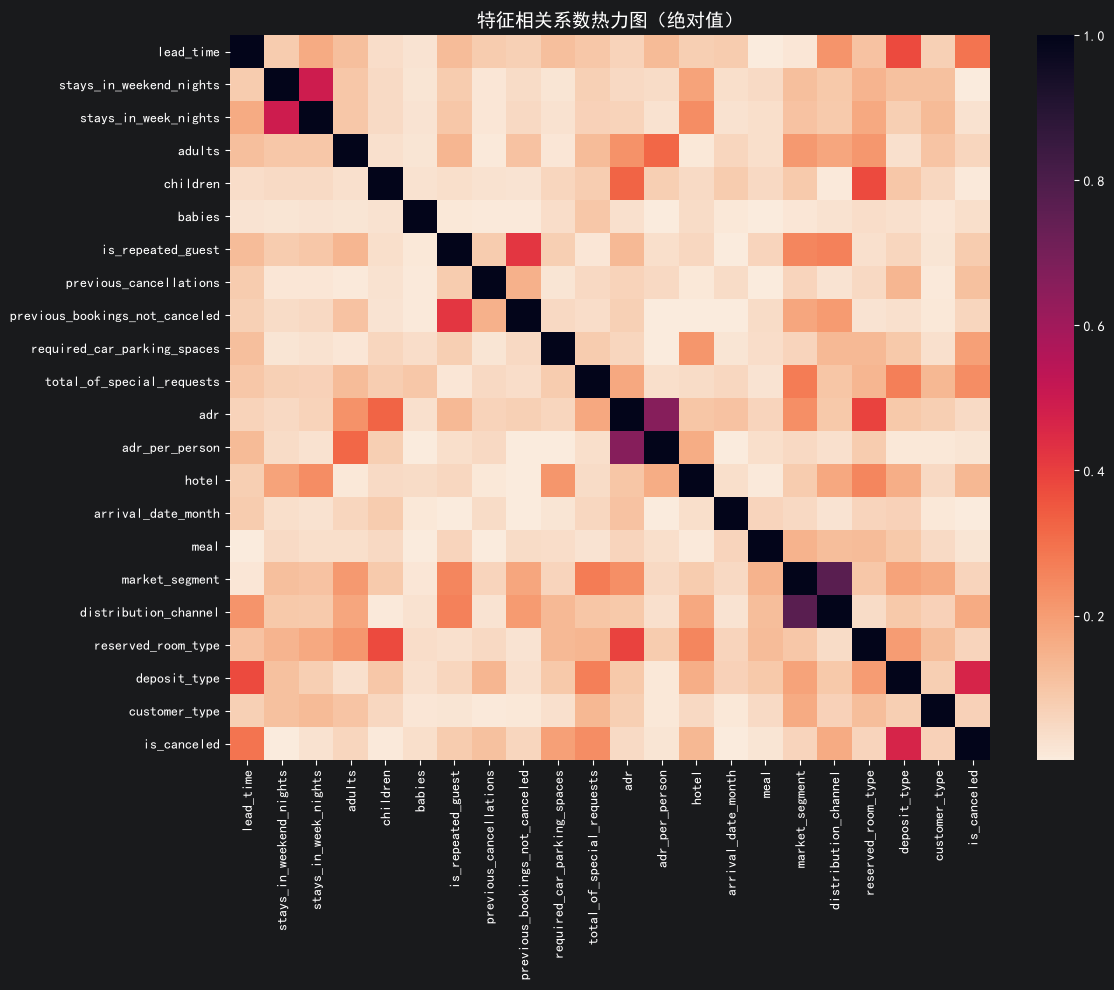

=====各特征与is_canceled的相关系数（按绝对值从大到小排序）=====
                                    相关系数   相关系数绝对值
deposit_type                    0.468706  0.468706
lead_time                       0.292930  0.292930
total_of_special_requests      -0.234925  0.234925
required_car_parking_spaces    -0.195696  0.195696
distribution_channel            0.167650  0.167650
hotel                          -0.137056  0.137056
previous_cancellations          0.110147  0.110147
is_repeated_guest              -0.083740  0.083740
customer_type                  -0.068276  0.068276
reserved_room_type             -0.062218  0.062218
market_segment                  0.059395  0.059395
adults                          0.058155  0.058155
previous_bookings_not_canceled -0.057363  0.057363
adr                             0.046558  0.046558
babies                         -0.032566  0.032566
stays_in_week_nights            0.025549  0.025549
adr_per_person                  0.017871  0.017871
meal                           -0.01720

In [85]:
#五、特征之间相关性分析
#1. 计算皮尔逊相关系数，输出每个特征与`is_canceled`的相关系数排序
#2. 绘制相关系数热力图
#3. 观察两点：
   #- 哪些特征和订单取消线性相关性强
   #- 查找特征之间高度线性相关的变量（多重共线性，两个特征信息高度重复）
num = [
    'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'is_repeated_guest',
    'previous_cancellations', 'previous_bookings_not_canceled',
    'required_car_parking_spaces', 'total_of_special_requests', 'adr', 'adr_per_person'
]
cat = [
    'hotel', 'arrival_date_month', 'meal', 'market_segment',
    'distribution_channel', 'reserved_room_type', 'deposit_type',
    'customer_type'
]
target = ['is_canceled']

ref = num + cat + target
train = df[ref].copy()

#类别变量编码
le_dict = {}
for col in cat:
    le = LabelEncoder()
    train[col] = le.fit_transform(train[col].astype(str))
    le_dict[col] = le

#连续变量归一化
scaler = MinMaxScaler()
train[num] = scaler.fit_transform(train[num])

#相关系数热力图
plt.figure(figsize=(12, 10))
corr_mat = train.corr().abs()
sns.heatmap(corr_mat, cmap=sns.cm.rocket_r)
plt.title("特征相关系数热力图（绝对值）", fontsize=14)
plt.tight_layout()
plt.show()
# 计算每个特征和目标is_canceled的相关系数，按绝对值降序排列
corr_with_target = train.corr()['is_canceled'].drop('is_canceled')
corr_sorted = corr_with_target.abs().sort_values(ascending=False)

# 拼接原始相关系数和绝对值，方便查看正负相关性
corr_result = pd.DataFrame({
    '相关系数': corr_with_target[corr_sorted.index],
    '相关系数绝对值': corr_sorted
})
print("=====各特征与is_canceled的相关系数（按绝对值从大到小排序）=====")
print(corr_result)

In [114]:
#六、逐个看每个变量的业务含义：
#- 判断这个变量是**预订发生前就可以获取**，还是**订单生成之后才产生**
#- 事后产生的变量属于泄露特征，无度量意义，类别太多且关联性很弱。记录下来，后续数据清洗阶段直接剔除
#泄露数据 reservation_status_date reservation_status booking_changes days_in_waiting_list is_canceled assigned_room_type country agent company

DA 总结，输出预处理方案清单

汇总上面所有发现，写清楚后续数据清洗要做的全部操作：
1. 需要删除哪些泄露特征
2. 各列缺失值处理方法
3. 哪些连续特征存在异常值，处理方式
4. 哪些类别特征需要编码

In [115]:
import pandas as pd

# 假设你的数据已经读入为 df，且包含 deposit_type 和 is_canceled 两列
# df = pd.read_csv('hotel_bookings.csv')

# 按押金类型分组，统计总订单数、取消订单数和取消率
deposit_stats = df.groupby('deposit_type')['is_canceled'].agg(
    总订单='count',
    取消订单='sum'
).reset_index()

deposit_stats['取消率'] = deposit_stats['取消订单'] / deposit_stats['总订单']

# 按取消率降序排列
deposit_stats = deposit_stats.sort_values('取消率', ascending=False).reset_index(drop=True)

print(deposit_stats)

  deposit_type     总订单   取消订单       取消率
0   Non Refund   14587  14494  0.993624
1   No Deposit  104641  29694  0.283770
2   Refundable     162     36  0.222222
